<a href="https://colab.research.google.com/github/jpnoug/spectropy/blob/main/correction_masse_air_differentielle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/jpnoug/spectropy/blob/main/correction_masse_air_differentielle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Correction de masse d'air différentielle — cible / étoile de référence

**Mode d'emploi (Colab)** : *Exécution → Tout exécuter*. Deux fenêtres de téléchargement s'ouvrent à tour de rôle : d'abord le spectre **traité** de la cible (déjà divisé par la réponse instrumentale), puis le spectre traité de l'étoile de référence qui a servi à calculer cette réponse. Le spectre corrigé, la courbe de correction et le graphe sont ensuite téléchargés automatiquement.

**Le problème.** La réponse instrumentale calculée sur l'étoile de référence (méthode de C. Buil) contient l'extinction atmosphérique à la masse d'air de la référence, `X_réf`. Si la cible a été observée à une autre masse d'air `X_cible`, son spectre traité garde une erreur de couleur :

`F_traité(λ) = F_vrai(λ) · 10^(−0,4 · k(λ) · ΔX)`  avec  `ΔX = X_cible − X_réf`

et `k(λ)` la courbe d'extinction du site (mag par masse d'air).

**La correction.** On multiplie le spectre traité par

`C(λ) = 10^(0,4 · [k(λ) − k(λ₀)] · ΔX)`

normalisée à 1 en `λ₀` (6637 Å par défaut), pour ne pas toucher au niveau du spectre. Si ΔX < 0 (cible plus haute que la référence), la cible ressort trop bleue et `C` atténue le bleu ; si ΔX > 0, l'inverse.

**Ce que fait le notebook.**
1. Lit dans les en-têtes ISIS le site (`GEO_LAT`, `GEO_LONG`, `GEO_ELEV`), l'heure (`JD-OBS`, `JD-MID`) et le nom des objets (`OBJNAME`) ; les coordonnées sont obtenues auprès de SIMBAD/Sesame à partir du nom (la date de la nuit ajoutée par ISIS, ex. `_0922` ou `0904` collé au nom, est retirée).
2. Calcule la masse d'air **moyenne sur toute la séquence de poses** (Kasten & Young 1989), pour la cible et pour la référence.
3. Construit `k(λ)` avec un modèle physique : diffusion Rayleigh à la pression du site + aérosols (loi d'Ångström, AOD au choix, par exemple tirée d'observation_pad) + ozone (bande de Chappuis).
4. Écrit le spectre corrigé et la courbe `C(λ)` sur la même grille que le spectre d'entrée, et trace le résultat.

**Application dans ISIS (sans ce notebook)** : multiplier le spectre traité de la cible par le fichier `…_masseair_courbe`.

**Hors du champ de ce notebook** :
- *Bandes telluriques* (O₂ B, O₂ A, H₂O) : une courbe lisse ne corrige pas la différence de profondeur des bandes. Elles sont seulement signalées sur le graphe ; leur correction relève du gabarit tellurique du notebook de réponse instrumentale (étape 2, gabarit optimisé pour la cible).
- *Second ordre*, *réfraction différentielle* et *pertes de fente* : non corrigés. `LAM_MAX` permet de couper la sortie au-delà d'une longueur d'onde.

In [1]:
# ============================ PARAMÈTRES ============================
FICHIER_CIBLE     = None   # None = fenêtre de téléchargement (Colab). Spectre 1D ISIS de la cible, TRAITÉ (divisé par la réponse)
FICHIER_REFERENCE = None   # None = fenêtre de téléchargement. Spectre 1D ISIS traité de l'étoile de référence (seul son en-tête sert)

# --- longueur d'onde pivot : la correction vaut 1 à LAM0 ---
LAM0 = 6637.               # Å

# --- aérosols ---
LIGNE_OBSERVATION_PAD = ""   # facultatif : colle ici la ou les lignes d'observation_pad, par exemple
                             #   "[21:17 TU] AOD 550nm : 0.131 (CAMS model)"
                             #   "[21:17 TU] AERONET : Toulouse_MF (9 km) / AOD500 0.014 / Angstrom 0.67 / lunar / 2026-07-23 21:03 TU"
                             # Si elle est remplie, elle remplace AOD / LAM_AOD (et ANGSTROM pour AERONET).
SOURCE_AOD = "cams"          # si les deux lignes sont collées : "cams" (modèle, à l'heure de l'observation) ou "aeronet" (mesure, vérifier sa date)
AOD        = 0.10            # épaisseur optique des aérosols à LAM_AOD (utilisée si aucune ligne n'est collée)
LAM_AOD    = 5500.           # Å : longueur d'onde de AOD (5500 pour CAMS, 5000 pour AERONET)
ANGSTROM   = 1.3             # exposant d'Ångström : 1,3 = valeur continentale classique ; < 1 = aérosols plus gros (poussières)

# --- ozone ---
OZONE_DU = 300.              # colonne d'ozone en unités Dobson (300 en moyenne aux latitudes moyennes)

# --- masses d'air : None = calculées à partir des en-têtes ; un nombre = imposé ---
X_CIBLE = None
X_REF   = None
DELTA_X = None               # None = X_CIBLE − X_REF ; un nombre = imposé directement (prioritaire)

# --- coordonnées : None = lues dans l'en-tête si présentes, sinon résolues par nom (SIMBAD / Sesame) ---
NOM_CIBLE, NOM_REF     = None, None      # ex. "del Cep", "HD 216916" : remplace le nom tiré de OBJNAME
COORD_CIBLE, COORD_REF = None, None      # ex. "22h29m10.3s +58d24m55s" : évite la requête SIMBAD

# --- site : None = lu dans l'en-tête (GEO_LAT / GEO_LONG / GEO_ELEV) ---
SITE = None                  # ex. (43.517, 1.509, 150) = (latitude °N, longitude °E, altitude m)

# --- sorties ---
LAM_MAX = None               # Å : rien n'est écrit au-delà (ex. 6900 tant que le second ordre n'est pas corrigé). None = tout
PREFIXE_SORTIE = None        # None = nom du spectre de la cible

In [2]:
# ============================ OUTILS ============================
import os, re
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from astropy.io import fits
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, Angle
import astropy.units as u

def trouver(nom, invite=""):
    # Renvoie le nom d'un fichier présent ; sinon, dans Colab, ouvre la fenêtre de téléchargement.
    if nom and os.path.exists(nom):
        return nom
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(nom or invite)
    print(invite or f"Sélectionne le fichier « {nom} » :")
    recu = files.upload()
    if not recu:
        raise RuntimeError("Aucun fichier reçu.")
    return list(recu.keys())[0]

def lire_1d(chemin):
    # Renvoie (lam en Å, flux, en-tête ou None). FITS 1D ISIS (CRVAL1/CDELT1) ou texte deux colonnes (.dat).
    if os.path.splitext(chemin)[1].lower() in ('.fit', '.fits', '.fts'):
        with fits.open(chemin) as h:
            hdu = next(x for x in h if x.data is not None and np.ndim(x.data) == 1)
            hdr = hdu.header.copy()
            flux = np.asarray(hdu.data, float)
        n = np.arange(flux.size)
        lam = hdr['CRVAL1'] + (n + 1 - hdr.get('CRPIX1', 1)) * hdr['CDELT1']
        return lam, flux, hdr
    t = np.loadtxt(chemin, usecols=(0, 1))
    return t[:, 0], t[:, 1], None

# ---------- site, heure, coordonnées ----------
def _angle(v, unite=u.deg):
    if isinstance(v, str):
        v = v.strip()
        try:
            return float(v)
        except ValueError:
            return Angle(v, unit=unite).deg
    return float(v)

def site_depuis_entete(h):
    for kl, kL, kh in (('GEO_LAT', 'GEO_LONG', 'GEO_ELEV'), ('SITELAT', 'SITELONG', 'SITEELEV'),
                       ('LAT-OBS', 'LONG-OBS', 'ALT-OBS'), ('OBSLAT', 'OBSLONG', 'OBSALT')):
        if h is not None and kl in h and kL in h:
            return _angle(h[kl]), _angle(h[kL]), float(h.get(kh, 0.0))
    return None

def intervalle_pose(h):
    # (JD de début, durée de la séquence en jours) ; JD-MID donne la vraie durée de la séquence (poses + lectures).
    if 'JD-OBS' in h:
        jd0 = float(h['JD-OBS'])
    elif 'DATE-OBS' in h:
        jd0 = Time(h['DATE-OBS'], scale='utc').jd
    else:
        raise KeyError("Ni JD-OBS ni DATE-OBS dans l'en-tête : impose X_CIBLE / X_REF ou DELTA_X.")
    if 'JD-MID' in h and float(h['JD-MID']) > jd0:
        return jd0, 2 * (float(h['JD-MID']) - jd0), "JD-OBS → 2 × (JD-MID − JD-OBS)"
    return jd0, float(h.get('EXPTIME', 0.0)) / 86400., "JD-OBS + EXPTIME"

def nom_depuis_entete(h):
    # ISIS ajoute la date de la nuit (MMJJ) au nom de l'objet : del_cep_0922, HD_216916_0922, HD2169160904.
    # On ne retire QUE cette date (lue dans DATE-OBS / JD-OBS, ou la veille pour une nuit passée minuit),
    # pour ne jamais rogner un vrai numéro de catalogue.
    brut = str(h.get('OBJNAME', h.get('OBJECT', ''))).strip()
    candidats = []
    try:
        t = Time(float(h['JD-OBS']), format='jd', scale='utc') if 'JD-OBS' in h else Time(h['DATE-OBS'], scale='utc')
        for j in (0, -1, 1):
            mmjj = (t + j * u.day).strftime('%m%d')
            m = re.match(rf'^(.*?\S)[_ \-]?{mmjj}$', brut)
            if m:
                candidats.append(m.group(1).rstrip('_- '))
    except Exception:
        pass
    candidats.append(brut)
    return [n.replace('_', ' ').strip() for n in dict.fromkeys(candidats) if n]

def coord_depuis_entete(h):
    for kr, kd in (('RA', 'DEC'), ('OBJCTRA', 'OBJCTDEC'), ('CRVAL2', 'CRVAL3')):
        if kr in h and kd in h:
            try:
                ra, de = h[kr], h[kd]
                if isinstance(ra, str) and (':' in ra or ' ' in ra.strip()):
                    return SkyCoord(ra, de, unit=(u.hourangle, u.deg))
                return SkyCoord(float(ra) * u.deg, float(de) * u.deg)
            except Exception:
                pass
    return None

def resoudre(h, nom_impose, coord_imposee, role):
    if coord_imposee:
        c = SkyCoord(coord_imposee, unit=(u.hourangle, u.deg)) if isinstance(coord_imposee, str) else coord_imposee
        return c, "COORD imposées"
    if nom_impose is None and h is not None:
        c = coord_depuis_entete(h)
        if c is not None:
            return c, "en-tête"
    noms = [nom_impose] if nom_impose else nom_depuis_entete(h)
    for n in noms:
        try:
            return SkyCoord.from_name(n), f"SIMBAD/Sesame « {n} »"
        except Exception:
            continue
    raise RuntimeError(f"{role} : coordonnées introuvables pour {noms}. Renseigne NOM_… ou COORD_… dans les paramètres.")

def masse_air(alt_deg):
    # Kasten & Young (1989), altitude vraie (sans réfraction), valable jusqu'à l'horizon.
    a = np.asarray(alt_deg, float)
    return 1.0 / (np.sin(np.radians(a)) + 0.50572 * (a + 6.07995) ** -1.6364)

def masse_air_moyenne(coord, lieu, jd0, duree, n=41):
    t = Time(jd0 + np.linspace(0, duree, n), format='jd', scale='utc')
    alt = coord.transform_to(AltAz(obstime=t, location=lieu)).alt.deg   # pression nulle = pas de réfraction
    if np.any(alt <= 0):
        raise ValueError("Objet sous l'horizon pendant la pose : vérifie le site, l'heure ou les coordonnées.")
    X = masse_air(alt)
    return float(X.mean()), float(alt.mean()), float(X.min()), float(X.max())

# ---------- extinction atmosphérique k(λ) en mag / masse d'air ----------
# Ozone, bande de Chappuis : sections efficaces (1e-21 cm²) à température ambiante, valeurs arrondies
_O3_L = np.array([3500, 4000, 4500, 4750, 5000, 5250, 5500, 5750, 6000, 6250, 6500, 6750, 7000, 7500, 8000, 9000, 10000.])
_O3_S = np.array([0.00, 0.01, 0.30, 0.75, 1.55, 2.35, 3.30, 4.60, 5.10, 4.20, 2.50, 1.70, 0.90, 0.45, 0.30, 0.10, 0.05])

def pression_site(alt_m):
    return 1013.25 * (1 - 2.25577e-5 * alt_m) ** 5.25588            # atmosphère standard (hPa)

def tau_rayleigh(lam_A, p_hPa):
    l = lam_A / 1e4                                                  # µm
    return 0.008569 * l ** -4 * (1 + 0.0113 * l ** -2 + 0.00013 * l ** -4) * p_hPa / 1013.25   # Hansen & Travis (1974)

def tau_aerosols(lam_A, aod, lam_aod, alpha):
    return aod * (lam_A / lam_aod) ** -alpha

_O3_INTERP = PchipInterpolator(_O3_L, _O3_S)                          # interpolation douce, sans dépassement

def tau_ozone(lam_A, du):
    return np.clip(_O3_INTERP(np.clip(lam_A, _O3_L[0], _O3_L[-1])), 0, None) * 1e-21 * du * 2.687e16

def k_ext(lam_A, alt_m, aod, lam_aod, alpha, du):
    tr = tau_rayleigh(lam_A, pression_site(alt_m))
    ta = tau_aerosols(lam_A, aod, lam_aod, alpha)
    to = tau_ozone(lam_A, du)
    return 1.0857 * (tr + ta + to), 1.0857 * tr, 1.0857 * ta, 1.0857 * to

def lire_observation_pad(texte, source):
    # Renvoie (aod, lam_aod, alpha ou None, description) ou None.
    cams = re.search(r'AOD\s*550\s*nm\s*:\s*([0-9.]+)', texte or "", re.I)
    aer = re.search(r'AOD500\s*([0-9.]+)', texte or "", re.I)
    ang = re.search(r'Angstrom\s*([0-9.]+)', texte or "", re.I)
    if aer and (source == "aeronet" or not cams):
        return float(aer.group(1)), 5000., (float(ang.group(1)) if ang else None), "AERONET (AOD500)"
    if cams:
        return float(cams.group(1)), 5500., None, "CAMS (AOD 550 nm)"
    return None

# ---------- écriture ----------
def ecrire_dat(chemin, lam, y):
    with open(chemin, 'w', newline='') as f:
        for a, b in zip(lam, y):
            f.write(f"{a:.4f} {b:.6g}\r\n")
    return chemin

def ecrire_fits(chemin, data, hdr, cles, notes, crval=None):
    h = hdr.copy()
    if crval is not None:
        h['CRVAL1'] = float(crval); h['CRPIX1'] = 1.0
    for k in ('BZERO', 'BSCALE', 'BLANK'):
        h.remove(k, ignore_missing=True)
    for k, (v, c) in cles.items():
        h[k] = (v, c)
    for n in notes:
        h['HISTORY'] = n
    fits.PrimaryHDU(np.asarray(data, np.float32), header=h).writeto(chemin, overwrite=True)
    return chemin

In [3]:
# ============================ LECTURE ET MASSES D'AIR ============================
FICHIER_CIBLE = trouver(FICHIER_CIBLE, "▶ 1/2 — Choisis le spectre TRAITÉ de la cible (.fit / .fits) :")
lam, F, hdr = lire_1d(FICHIER_CIBLE)
FICHIER_REFERENCE = trouver(FICHIER_REFERENCE, "▶ 2/2 — Choisis le spectre traité de l'étoile de référence (.fit / .fits) :")
lam_r, F_r, hdr_r = lire_1d(FICHIER_REFERENCE)
ext_entree = os.path.splitext(FICHIER_CIBLE)[1].lower().lstrip('.')
if ext_entree not in ('fit', 'fits', 'fts'):
    ext_entree = 'dat'

nn = np.flatnonzero(np.isfinite(F) & (F != 0))
print(f"Cible     : {os.path.basename(FICHIER_CIBLE)} — {lam[nn[0]]:.0f}–{lam[nn[-1]]:.0f} Å (non nul), pas {np.median(np.diff(lam)):.3f} Å")
print(f"Référence : {os.path.basename(FICHIER_REFERENCE)}")
if lam_r.size != lam.size or not np.allclose(lam_r, lam, atol=1e-3):
    print("  ⚠ Les deux spectres n'ont pas la même grille en λ : vérifie que la référence est bien celle de la cible (sans conséquence sur la correction).")

def calc_X(h, nom, coord, role, lieu):
    c, src = resoudre(h, nom, coord, role)
    jd0, duree, mode = intervalle_pose(h)
    X, alt, xmin, xmax = masse_air_moyenne(c, lieu, jd0, duree)
    t0 = Time(jd0, format='jd', scale='utc').iso[:19]
    print(f"  {role:9s}: {c.to_string('hmsdms', precision=0)}  ({src})")
    print(f"             début {t0} TU, séquence {duree * 1440:.1f} min ({mode})")
    print(f"             hauteur moyenne {alt:.1f}°  →  X = {X:.4f}  (de {xmin:.4f} à {xmax:.4f} pendant la séquence)")
    return X, jd0 + duree / 2

besoin_X = DELTA_X is None and (X_CIBLE is None or X_REF is None)
if SITE is not None:
    lat, lon, alt_m = SITE
else:
    s = site_depuis_entete(hdr) or site_depuis_entete(hdr_r)
    if s is None:
        raise KeyError("Site absent des en-têtes : renseigne SITE = (latitude, longitude Est, altitude m).")
    lat, lon, alt_m = s
    s_r = site_depuis_entete(hdr_r)
    if s_r is not None and (abs(s_r[0] - lat) > 0.01 or abs(s_r[1] - lon) > 0.01):
        print(f"  ⚠ Site différent dans l'en-tête de la référence : {s_r} (on garde celui de la cible).")
lieu = EarthLocation(lat=lat * u.deg, lon=lon * u.deg, height=alt_m * u.m)
print(f"Site : {lat:.4f}° N, {lon:.4f}° E, {alt_m:.0f} m" + (" (paramètre SITE)" if SITE else " (en-tête)"))

if besoin_X:
    if hdr is None or hdr_r is None:
        raise ValueError("Spectre sans en-tête FITS : impose X_CIBLE et X_REF, ou DELTA_X.")
    print("Masses d'air moyennes sur la séquence de poses :")
    Xc, mid_c = (X_CIBLE, None) if X_CIBLE is not None else calc_X(hdr, NOM_CIBLE, COORD_CIBLE, "Cible", lieu)
    Xr, mid_r = (X_REF, None) if X_REF is not None else calc_X(hdr_r, NOM_REF, COORD_REF, "Référence", lieu)
    if mid_c and mid_r:
        dt = (mid_c - mid_r) * 1440
        print(f"  Référence prise {abs(dt):.0f} min {'avant' if dt > 0 else 'après'} la cible (milieux de séquence).")
else:
    Xc, Xr = X_CIBLE, X_REF
dX = float(DELTA_X) if DELTA_X is not None else Xc - Xr
print(f"\nΔX = X_cible − X_réf = {dX:+.4f}" + ("  (imposé)" if DELTA_X is not None else ""))
if abs(dX) <= 0.03:
    print("   |ΔX| ≤ 0,03 : la correction sera faible (≲ 1–1,5 % à 3800 Å).")

▶ 1/2 — Choisis le spectre TRAITÉ de la cible (.fit / .fits) :


Saving _del_cep_0912_20260912_835.fits to _del_cep_0912_20260912_835.fits
▶ 2/2 — Choisis le spectre traité de l'étoile de référence (.fit / .fits) :


Saving _hd_216916_0912_20260912_826.fits to _hd_216916_0912_20260912_826.fits
Cible     : _del_cep_0912_20260912_835.fits — 3600–7619 Å (non nul), pas 0.500 Å
Référence : _hd_216916_0912_20260912_826.fits
Site : 43.5173° N, 1.5086° E, 150 m (en-tête)
Masses d'air moyennes sur la séquence de poses :
  Cible    : 22h29m10s +58d24m55s  (SIMBAD/Sesame « del cep »)
             début 2026-09-12 20:02:24 TU, séquence 4.9 min (JD-OBS → 2 × (JD-MID − JD-OBS))
             hauteur moyenne 59.8°  →  X = 1.1565  (de 1.1528 à 1.1602 pendant la séquence)
  Référence: 22h56m24s +41d36m14s  (SIMBAD/Sesame « HD 216916 »)
             début 2026-09-12 19:49:09 TU, séquence 6.9 min (JD-OBS → 2 × (JD-MID − JD-OBS))
             hauteur moyenne 51.7°  →  X = 1.2733  (de 1.2628 à 1.2840 pendant la séquence)
  Référence prise 12 min avant la cible (milieux de séquence).

ΔX = X_cible − X_réf = -0.1169


In [4]:
# ============================ COURBE D'EXTINCTION ET CORRECTION ============================
aod, lam_aod, alpha, src_aod = AOD, LAM_AOD, ANGSTROM, "paramètres AOD / LAM_AOD / ANGSTROM"
pad = lire_observation_pad(LIGNE_OBSERVATION_PAD, SOURCE_AOD.lower())
if pad is not None:
    aod, lam_aod, a_pad, src_aod = pad
    if a_pad is not None:
        alpha = a_pad
    src_aod = "observation_pad, " + src_aod
elif LIGNE_OBSERVATION_PAD.strip():
    print("⚠ Ligne d'observation_pad non reconnue : on garde AOD / LAM_AOD / ANGSTROM.")

P = pression_site(alt_m)
k, kR, kA, kO = k_ext(lam, alt_m, aod, lam_aod, alpha, OZONE_DU)
k0 = float(np.interp(LAM0, lam, k))
C = 10 ** (0.4 * (k - k0) * dX)
Fc = F * C

print(f"Modèle d'extinction : Rayleigh à {P:.0f} hPa ({alt_m:.0f} m) + aérosols AOD {aod:.3f} à {lam_aod:.0f} Å, α = {alpha:.2f} ({src_aod}) + ozone {OZONE_DU:.0f} DU")
print(f"\n{'λ (Å)':>7} {'k total':>8} {'Rayleigh':>9} {'aérosols':>9} {'ozone':>6} {'k − k(λ0)':>10} {'correction':>11}")
for l in (3800, 4000, 4500, 5000, 5500, 6000, LAM0, 7000, 7500):
    if lam[0] <= l <= lam[-1]:
        i = np.argmin(np.abs(lam - l))
        print(f"{l:7.0f} {k[i]:8.3f} {kR[i]:9.3f} {kA[i]:9.3f} {kO[i]:6.3f} {k[i] - k0:+10.3f} {100 * (C[i] - 1):+10.2f} %")
print(f"(k en mag par masse d'air ; correction = facteur appliqué au spectre, pour ΔX = {dX:+.4f})")

Modèle d'extinction : Rayleigh à 995 hPa (150 m) + aérosols AOD 0.100 à 5500 Å, α = 1.30 (paramètres AOD / LAM_AOD / ANGSTROM) + ozone 300 DU

  λ (Å)  k total  Rayleigh  aérosols  ozone  k − k(λ0)  correction
   3800    0.651     0.475     0.176  0.000     +0.500      -5.24 %
   4000    0.548     0.384     0.164  0.000     +0.397      -4.19 %
   4500    0.380     0.236     0.141  0.003     +0.228      -2.43 %
   5000    0.290     0.153     0.123  0.014     +0.138      -1.48 %
   5500    0.241     0.104     0.109  0.029     +0.090      -0.96 %
   6000    0.214     0.073     0.097  0.045     +0.063      -0.68 %
   6637    0.151     0.048     0.085  0.018     +0.000      +0.00 %
   7000    0.126     0.039     0.079  0.008     -0.025      +0.27 %
   7500    0.106     0.029     0.073  0.004     -0.045      +0.49 %
(k en mag par masse d'air ; correction = facteur appliqué au spectre, pour ΔX = -0.1169)


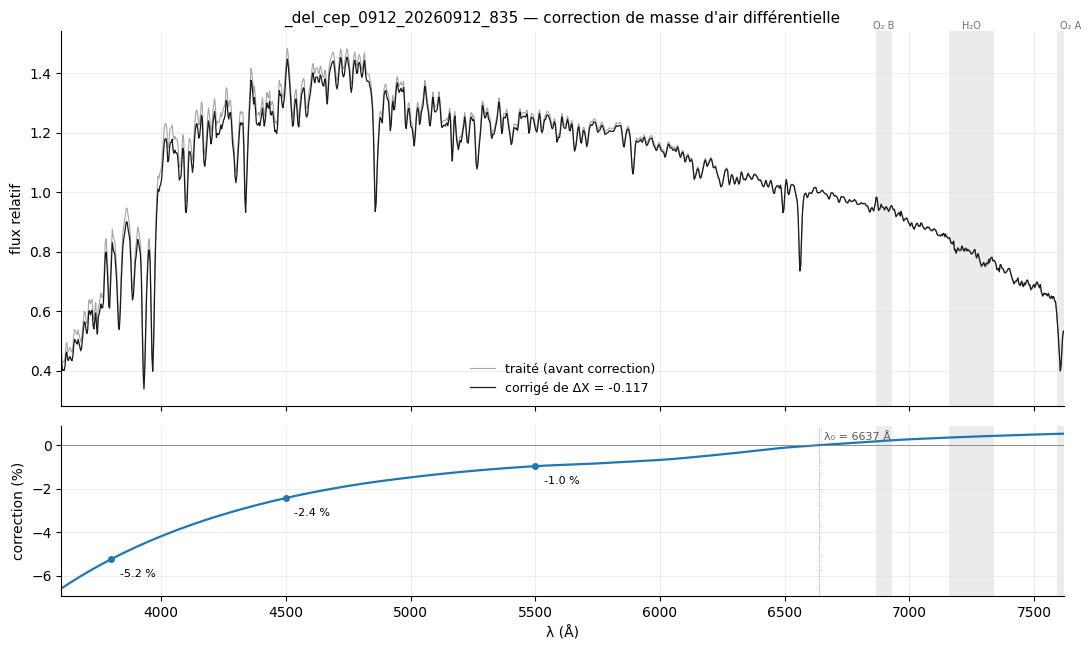

Zones grisées : bandes telluriques, non corrigées par cette courbe lisse.


In [5]:
# ============================ GRAPHE ============================
TELL = [("O₂ B", 6865, 6930), ("H₂O", 7160, 7340), ("O₂ A", 7590, 7700)]
base = PREFIXE_SORTIE or os.path.splitext(os.path.basename(FICHIER_CIBLE))[0]
ok = np.isfinite(F) & (F != 0)
x0, x1 = lam[ok][0], lam[ok][-1]
if LAM_MAX:
    x1 = min(x1, LAM_MAX)
s = ok & (lam >= x0) & (lam <= x1)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
a1.plot(lam[s], F[s], color='0.65', lw=0.8, label="traité (avant correction)")
a1.plot(lam[s], Fc[s], color='0.1', lw=0.9, label=f"corrigé de ΔX = {dX:+.3f}")
a1.set_ylabel("flux relatif")
a1.set_title(f"{base} — correction de masse d'air différentielle", fontsize=11)
a1.legend(frameon=False, loc='best', fontsize=9)

a2.plot(lam[s], 100 * (C[s] - 1), color='tab:blue', lw=1.6)
a2.axhline(0, color='0.5', lw=0.6)
a2.axvline(LAM0, color='0.5', lw=0.6, ls=':')
a2.annotate(f"λ₀ = {LAM0:.0f} Å", (LAM0, 0), xytext=(4, 4), textcoords='offset points', fontsize=8, color='0.35')
for l in (3800, 4500, 5500):
    if x0 <= l <= x1:
        i = np.argmin(np.abs(lam - l))
        a2.plot(lam[i], 100 * (C[i] - 1), 'o', ms=4, color='tab:blue')
        a2.annotate(f"{100 * (C[i] - 1):+.1f} %", (lam[i], 100 * (C[i] - 1)), xytext=(6, -13), textcoords='offset points', fontsize=8)
a2.set_ylabel("correction (%)")
a2.set_xlabel("λ (Å)")

for ax in (a1, a2):
    for nom, a, b in TELL:
        if a < x1 and b > x0:
            ax.axvspan(a, b, color='0.92', zorder=0, lw=0)
    ax.grid(True, color='0.9', lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)
for nom, a, b in TELL:
    if a < x1 and b > x0:
        a1.text((a + b) / 2, 1.0, nom, transform=a1.get_xaxis_transform(), ha='center', va='bottom', fontsize=7, color='0.45')
a2.set_xlim(x0, x1)
plt.tight_layout()
fichier_png = f"{base}_masseair.png"
plt.savefig(fichier_png, dpi=130)
plt.show()
print("Zones grisées : bandes telluriques, non corrigées par cette courbe lisse.")

In [6]:
# ============================ SORTIES (même grille que le spectre ISIS) ============================
garde = np.ones(lam.size, bool) if not LAM_MAX else (lam <= LAM_MAX)
crval = None if garde.all() else float(lam[garde][0])
cles = {
    'AIRMASS':  (round(Xc, 4) if Xc is not None else -1.0, "Mean airmass of the target sequence"),
    'AIRM_REF': (round(Xr, 4) if Xr is not None else -1.0, "Mean airmass of the response reference star"),
    'DELTA_X':  (round(dX, 4), "X_target - X_ref used for correction"),
    'XC_LAM0':  (float(LAM0), "[Angstrom] pivot wavelength, correction = 1"),
    'XC_AOD':   (round(float(aod), 4), "aerosol optical depth at XC_LAMA"),
    'XC_LAMA':  (float(lam_aod), "[Angstrom] wavelength of XC_AOD"),
    'XC_ANGS':  (round(float(alpha), 3), "aerosol Angstrom exponent"),
    'XC_O3DU':  (float(OZONE_DU), "[DU] ozone column"),
    'XC_PRES':  (round(float(P), 1), "[hPa] site pressure for Rayleigh"),
}
ref_nom = os.path.basename(FICHIER_REFERENCE)
notes = [f"Airmass correction: C = 10^(0.4*(k-k({LAM0:.0f}A))*dX), dX={dX:+.4f}",
         f"k = Rayleigh + aerosols + ozone; ref: {ref_nom}"[:72]]

if ext_entree == 'dat':
    sorties = [ecrire_dat(f"{base}_masseair.dat", lam[garde], Fc[garde]),
               ecrire_dat(f"{base}_masseair_courbe.dat", lam[garde], C[garde])]
else:
    sorties = [ecrire_fits(f"{base}_masseair.{ext_entree}", Fc[garde], hdr, cles, notes + ["Spectrum corrected for differential airmass"], crval),
               ecrire_fits(f"{base}_masseair_courbe.{ext_entree}", C[garde], hdr, cles, notes + ["Correction curve: multiply the processed target by it"], crval)]
sorties.append(fichier_png)
print("Fichiers écrits :", *sorties, sep="\n   ")
print(f"\n→ Dans ISIS : multiplier le spectre traité de la cible par  {base}_masseair_courbe")
try:
    from google.colab import files
    for f_ in sorties:
        files.download(f_)
except ImportError:
    pass

Fichiers écrits :
   _del_cep_0912_20260912_835_masseair.fits
   _del_cep_0912_20260912_835_masseair_courbe.fits
   _del_cep_0912_20260912_835_masseair.png

→ Dans ISIS : multiplier le spectre traité de la cible par  _del_cep_0912_20260912_835_masseair_courbe


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>